In [1]:
import os
import math
import random
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModel, DataCollatorWithPadding

# RDKit for SMILES validation
from rdkit import Chem

# Metrics
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score

# Reproducibility
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


d:\leash-BELKA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device(type='cuda')

In [2]:
class CFG:
    data_path = "train_multilabel_combined.parquet"  # change if needed
    smiles_col = "molecule_smiles"                            # change if needed
    label_cols = ["BRD4", "HSA", "sEH"]              # change if needed

    model_name = "seyonec/ChemBERTa-zinc-base-v1"

    # Training
    epochs = 5
    train_batch_size = 32
    valid_batch_size = 64
    lr_heads = 2e-3             # heads/attention learning rate
    lr_encoder = 5e-5           # if you later unfreeze some layers
    weight_decay = 1e-4

    # Tokenization
    max_length = 128

    # Balancing / splitting
    max_per_pattern = None      # e.g., 500 to downsample; None keeps all
    valid_size = 0.15
    test_size = 0.15

    # Misc
    num_workers = 0
    pin_memory = True

CFG.__dict__


mappingproxy({'__module__': '__main__',
              'data_path': 'train_multilabel_combined.parquet',
              'smiles_col': 'molecule_smiles',
              'label_cols': ['BRD4', 'HSA', 'sEH'],
              'model_name': 'seyonec/ChemBERTa-zinc-base-v1',
              'epochs': 5,
              'train_batch_size': 32,
              'valid_batch_size': 64,
              'lr_heads': 0.002,
              'lr_encoder': 5e-05,
              'weight_decay': 0.0001,
              'max_length': 128,
              'max_per_pattern': None,
              'valid_size': 0.15,
              'test_size': 0.15,
              'num_workers': 0,
              'pin_memory': True,
              '__dict__': <attribute '__dict__' of 'CFG' objects>,
              '__weakref__': <attribute '__weakref__' of 'CFG' objects>,
              '__doc__': None})

In [3]:
df = pd.read_parquet(CFG.data_path)
# Basic checks
assert CFG.smiles_col in df.columns, f"Missing SMILES column: {CFG.smiles_col}"
for c in CFG.label_cols:
    assert c in df.columns, f"Missing label column: {c}"
df.head()


,molecule_smiles,BRD4,HSA,sEH
0,O=C(N[Dy])[C@H]1CC[C@H](CNc2nc(NCCC3SCCS3)nc(N...,0,0,1
1,Cc1cnc(CCNc2nc(NCCN3CC[C@@H](O)C3)nc(Nc3cc4ccc...,0,0,0
2,Cc1cc(C)c(CNc2nc(NCc3c(F)cccc3N3CCCC3)nc(N[C@H...,0,0,0
3,O=C1OCc2cc(Nc3nc(NCC4CCCC5(CCC5)C4O)nc(NC[C@H]...,0,0,1
4,O=C(N[Dy])c1cc(F)c(Nc2nc(NCCC3CSC3)nc(Nc3cccc(...,0,0,0


In [4]:
def is_valid_smiles(smi: str) -> bool:
    try:
        return Chem.MolFromSmiles(str(smi)) is not None
    except Exception:
        return False

# Create a label tuple "pattern" for stratification/ balancing
def make_pattern_row(row):
    return tuple(int(row[c]) for c in CFG.label_cols)

df = df.copy()
df["pattern"] = df.apply(make_pattern_row, axis=1)
df["is_valid"] = df[CFG.smiles_col].map(is_valid_smiles)
df["is_valid"].value_counts()


is_valid
True    2709762
Name: count, dtype: int64

In [5]:
from rdkit import Chem
import numpy as np
import pandas as pd
from typing import List, Optional

def validated_downsample(
    df: pd.DataFrame,
    smiles_col: str = "smiles",                # change to "molecule_smiles" if that's your column
    target_cols: List[str] = ["BRD4", "HSA", "sEH"],
    base_n: int = 50_000,                      # target count for non-binders (pattern "000")
    random_state: int = 42
) -> pd.DataFrame:
    """
    Robust downsampling with SMILES validation.
    - Validates SMILES
    - Creates a string pattern like "010"
    - Downsamples ONLY the non-binder pattern "000" to at most base_n
    - Keeps all binder patterns unchanged
    - Returns a shuffled DataFrame with a tuple `pattern` column for stratification

    Returns:
        DataFrame with:
          - original columns
          - `pattern` as a tuple (e.g., (0,1,0))
        and without helper columns.
    """
    # --- Validations ---
    required = set(target_cols + [smiles_col])
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    # --- Copy and compute helper columns ---
    x = df.copy()
    # ensure labels are 0/1 ints
    for c in target_cols:
        x[c] = pd.to_numeric(x[c], errors="coerce").fillna(0).astype(int)

    # pattern as string for grouping (e.g., '010')
    x["_pattern_str"] = x[target_cols].astype(str).agg(''.join, axis=1)

    # validate SMILES
    def _is_valid(smi):
        try:
            return Chem.MolFromSmiles(str(smi)) is not None
        except Exception:
            return False

    x["_is_valid"] = x[smiles_col].apply(_is_valid)
    x = x[x["_is_valid"]].copy()

    # --- Group by pattern string ---
    groups = dict(tuple(x.groupby("_pattern_str", sort=False)))

    # Non-binders
    nb = groups.get("000", pd.DataFrame())
    if not nb.empty:
        nb = nb.sample(n=min(base_n, len(nb)), random_state=random_state)

    # All binders (everything except "000")
    binders = [g for p, g in groups.items() if p != "000"]

    # Combine
    if len(binders) > 0:
        balanced = pd.concat([nb] + binders, axis=0)
    else:
        balanced = nb

    # Shuffle
    balanced = balanced.sample(frac=1.0, random_state=random_state).reset_index(drop=True)

    # Create tuple pattern for downstream stratification: (0,1,0)
    balanced["pattern"] = list(
        map(tuple, balanced[target_cols].astype(int).values.tolist())
    )

    # Drop helpers
    balanced = balanced.drop(columns=["_pattern_str", "_is_valid"], errors="ignore")

    return balanced


df_bal = validated_downsample(
    df,
    smiles_col=CFG.smiles_col,     # e.g., "smiles" or "molecule_smiles"
    target_cols=CFG.label_cols,    # ["BRD4","HSA","sEH"]
    base_n= 100_000
)


In [6]:
df_bal["pattern"].value_counts() 

pattern
(0, 0, 1)    644688
(1, 0, 0)    456070
(0, 1, 0)    328939
(0, 0, 0)    100000
(0, 1, 1)     79171
(1, 0, 1)       597
(1, 1, 0)       235
(1, 1, 1)        62
Name: count, dtype: int64

In [7]:
from sklearn.model_selection import train_test_split

# Stratify by the pattern so multilabel distribution is preserved
train_df, temp_df = train_test_split(
    df_bal, test_size=(CFG.valid_size + CFG.test_size),
    stratify=df_bal["pattern"], random_state=42
)

# Re-normalize for val/test split
rel_test = CFG.test_size / (CFG.valid_size + CFG.test_size + 1e-9)
valid_df, test_df = train_test_split(
    temp_df, test_size=rel_test, stratify=temp_df["pattern"], random_state=42
)

for name, part in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    print(name, part.shape, "unique patterns:", part["pattern"].nunique())


train (1126833, 6) unique patterns: 8
valid (241464, 6) unique patterns: 8
test (241465, 6) unique patterns: 8


In [8]:
tokenizer = AutoTokenizer.from_pretrained(CFG.model_name)

class SmilesDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, smiles_col: str, label_cols: list, tokenizer, max_length: int):
        self.df = frame.reset_index(drop=True)
        self.smiles_col = smiles_col
        self.label_cols = label_cols
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        smi = str(row[self.smiles_col])
        labels = row[self.label_cols].astype(float).values  # float for BCEWithLogits
        enc = self.tokenizer(
            smi,
            max_length=self.max_length,
            padding=False,
            truncation=True,
            return_tensors=None
        )
        return {
            "input_ids": torch.tensor(enc["input_ids"], dtype=torch.long),
            "attention_mask": torch.tensor(enc["attention_mask"], dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.float)
        }

train_ds = SmilesDataset(train_df, CFG.smiles_col, CFG.label_cols, tokenizer, CFG.max_length)
valid_ds = SmilesDataset(valid_df, CFG.smiles_col, CFG.label_cols, tokenizer, CFG.max_length)
test_ds  = SmilesDataset(test_df,  CFG.smiles_col, CFG.label_cols, tokenizer, CFG.max_length)

collator = DataCollatorWithPadding(tokenizer=tokenizer, padding=True, return_tensors="pt")

def make_loader(ds, batch_size, shuffle=False):
    return DataLoader(
        ds, batch_size=batch_size, shuffle=shuffle,
        num_workers=CFG.num_workers, pin_memory=CFG.pin_memory, collate_fn=collator
    )

train_loader = make_loader(train_ds, CFG.train_batch_size, shuffle=True)
valid_loader = make_loader(valid_ds, CFG.valid_batch_size, shuffle=False)
test_loader  = make_loader(test_ds,  CFG.valid_batch_size, shuffle=False)

len(train_ds), len(valid_ds), len(test_ds)


(1126833, 241464, 241465)

In [9]:
import torch
import torch.nn as nn
from transformers import AutoModel

class MultiLabelChemBERTaPlus(nn.Module):
    def __init__(
        self,
        model_name: str = "seyonec/ChemBERTa-zinc-base-v1",
        freeze_encoder: bool = True,
        disable_encoder_dropout: bool = True,
        n_labels: int = 3,
    ):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)

        self.freeze_encoder = freeze_encoder
        if self.freeze_encoder:
            for p in self.encoder.parameters():
                p.requires_grad = False
            if disable_encoder_dropout:
                self.encoder.eval()

        H = self.encoder.config.hidden_size

        self.attn_weights = nn.Sequential(
            nn.Linear(H, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
        )

        self.classifier = nn.Sequential(
            nn.Linear(H * 2, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, n_labels),
        )

    def forward(self, input_ids, attention_mask):
        if self.freeze_encoder:
            with torch.no_grad():
                enc_out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        else:
            enc_out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)

        last_hidden_state = enc_out.last_hidden_state  # (B, T, H)
        mask = attention_mask

        # Mean Pooling (safe)
        denom = mask.sum(dim=1, keepdim=True).clamp(min=1e-9)  # (B,1)
        mean_pool = (last_hidden_state * mask.unsqueeze(-1)).sum(dim=1) / denom  # (B,H)

        # Attention Pooling
        attn_scores = self.attn_weights(last_hidden_state).squeeze(-1)  # (B,T)
        attn_scores = attn_scores.masked_fill(mask == 0, -1e9)
        attn_weights = torch.softmax(attn_scores, dim=1)  # (B,T)
        attn_pool = torch.sum(last_hidden_state * attn_weights.unsqueeze(-1), dim=1)  # (B,H)

        pooled = torch.cat([mean_pool, attn_pool], dim=1)  # (B,2H)
        logits = self.classifier(pooled)  # (B, n_labels)
        return logits

    def unfreeze_last(self, k: int = 1):
        """
        Partially unfreeze the last k transformer layers for fine-tuning.
        Call before training; also set self.encoder.train() in your loop if needed.
        """
        encoder_stack = None
        for attr in ["encoder", "transformer", "bert", "roberta"]:
            if hasattr(self.encoder, attr):
                maybe = getattr(self.encoder, attr)
                if hasattr(maybe, "layer"):
                    encoder_stack = maybe.layer
                    break
                if hasattr(maybe, "layers"):
                    encoder_stack = maybe.layers
                    break
        if encoder_stack is None:
            raise AttributeError("Could not locate transformer layers to unfreeze.")
        for p in encoder_stack[-k:].parameters():
            p.requires_grad = True
        self.freeze_encoder = False


In [10]:
model = MultiLabelChemBERTaPlus(
    model_name=CFG.model_name,
    freeze_encoder=True,                 # start frozen
    disable_encoder_dropout=True,
    n_labels=len(CFG.label_cols)
).to(device)

criterion = nn.BCEWithLogitsLoss()

# Only train parameters that require grad (heads/attention by default)
optim = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=CFG.lr_heads, weight_decay=CFG.weight_decay
)

# LR scheduler (optional)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=CFG.epochs)


In [11]:
@torch.no_grad()
def evaluate(model, loader, criterion, threshold=0.5):
    model.eval()
    total_loss = 0.0
    all_logits = []
    all_targets = []

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        targets = batch["labels"].to(device)

        logits = model(input_ids=input_ids, attention_mask=attn)
        loss = criterion(logits, targets)
        total_loss += loss.item() * input_ids.size(0)

        all_logits.append(logits.detach().cpu())
        all_targets.append(targets.detach().cpu())

    all_logits = torch.cat(all_logits, dim=0).numpy()
    all_targets = torch.cat(all_targets, dim=0).numpy()

    # Sigmoid -> probs
    probs = 1 / (1 + np.exp(-all_logits))
    preds = (probs >= threshold).astype(int)

    # Metrics
    metrics = {}
    # F1 (macro)
    metrics["f1_macro"] = f1_score(all_targets, preds, average="macro", zero_division=0)
    # Per-label F1
    for i, name in enumerate(CFG.label_cols):
        metrics[f"f1_{name}"] = f1_score(all_targets[:, i], preds[:, i], average="binary", zero_division=0)

    # AUROC (handle cases with single class in y)
    for i, name in enumerate(CFG.label_cols):
        y = all_targets[:, i]
        if len(np.unique(y)) > 1:
            try:
                metrics[f"roc_auc_{name}"] = roc_auc_score(y, probs[:, i])
            except Exception:
                metrics[f"roc_auc_{name}"] = float("nan")
        else:
            metrics[f"roc_auc_{name}"] = float("nan")

    # mAP (macro-PR AUC)
    pr_list = []
    for i in range(len(CFG.label_cols)):
        y = all_targets[:, i]
        if len(np.unique(y)) > 1:
            try:
                pr_list.append(average_precision_score(y, probs[:, i]))
            except Exception:
                pass
    metrics["mAP_macro"] = float(np.mean(pr_list)) if len(pr_list) > 0 else float("nan")

    avg_loss = total_loss / len(loader.dataset)
    return avg_loss, metrics


In [12]:
best_val = float("inf")
best_state = None

for epoch in range(1, CFG.epochs + 1):
    model.train()
    running = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{CFG.epochs}")
    for batch in pbar:
        input_ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        targets = batch["labels"].to(device)

        logits = model(input_ids=input_ids, attention_mask=attn)
        loss = criterion(logits, targets)

        optim.zero_grad(set_to_none=True)
        loss.backward()
        optim.step()

        running += loss.item() * input_ids.size(0)
        pbar.set_postfix(train_loss=running / (pbar.n + 1e-9))

    scheduler.step()

    # Validation
    val_loss, val_metrics = evaluate(model, valid_loader, criterion, threshold=0.5)
    print(f"\nEpoch {epoch}: val_loss={val_loss:.4f} | f1_macro={val_metrics['f1_macro']:.4f} | mAP={val_metrics['mAP_macro']:.4f}")
    for k, v in val_metrics.items():
        if k.startswith("f1_") and k != "f1_macro":
            print(f"  {k}: {v:.4f}")

    # Save best
    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

# Load best
if best_state is not None:
    model.load_state_dict(best_state)


Epoch 1/5: 100%|██████████| 35214/35214 [44:30<00:00, 13.19it/s, train_loss=8.75]   



Epoch 1: val_loss=0.2321 | f1_macro=0.8291 | mAP=0.9007
  f1_BRD4: 0.8576
  f1_HSA: 0.7497
  f1_sEH: 0.8800


Epoch 2/5: 100%|██████████| 35214/35214 [44:25<00:00, 13.21it/s, train_loss=8.1]  



Epoch 2: val_loss=0.2309 | f1_macro=0.8319 | mAP=0.9032
  f1_BRD4: 0.8660
  f1_HSA: 0.7490
  f1_sEH: 0.8809


Epoch 3/5: 100%|██████████| 35214/35214 [44:19<00:00, 13.24it/s, train_loss=7.75]



Epoch 3: val_loss=0.2221 | f1_macro=0.8421 | mAP=0.9100
  f1_BRD4: 0.8781
  f1_HSA: 0.7603
  f1_sEH: 0.8880


Epoch 4/5: 100%|██████████| 35214/35214 [44:28<00:00, 13.20it/s, train_loss=7.44] 



Epoch 4: val_loss=0.2110 | f1_macro=0.8457 | mAP=0.9142
  f1_BRD4: 0.8927
  f1_HSA: 0.7541
  f1_sEH: 0.8902


Epoch 5/5: 100%|██████████| 35214/35214 [44:34<00:00, 13.17it/s, train_loss=7.22] 



Epoch 5: val_loss=0.2062 | f1_macro=0.8503 | mAP=0.9163
  f1_BRD4: 0.8914
  f1_HSA: 0.7686
  f1_sEH: 0.8910


In [13]:
# Unfreeze last 1 transformer block and use a smaller LR on encoder
model.unfreeze_last(k=1)
model.encoder.train()  # enable dropout etc. for the unfrozen layers

# New optimizer with differential LRs
head_params = []
enc_params = []

for n, p in model.named_parameters():
    if p.requires_grad:
        if n.startswith("encoder."):
            enc_params.append(p)
        else:
            head_params.append(p)

optim = torch.optim.AdamW(
    [
        {"params": head_params, "lr": CFG.lr_heads, "weight_decay": CFG.weight_decay},
        {"params": enc_params,  "lr": CFG.lr_encoder, "weight_decay": CFG.weight_decay},
    ]
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optim, T_max=max(1, CFG.epochs // 2))
print("Unfroze last layer(s) and reset optimizer.")


Unfroze last layer(s) and reset optimizer.


In [14]:
best_val = float("inf")
best_state = None

for epoch in range(1, CFG.epochs + 1):
    model.train()
    running = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{CFG.epochs}")
    for batch in pbar:
        input_ids = batch["input_ids"].to(device)
        attn = batch["attention_mask"].to(device)
        targets = batch["labels"].to(device)

        logits = model(input_ids=input_ids, attention_mask=attn)
        loss = criterion(logits, targets)

        optim.zero_grad(set_to_none=True)
        loss.backward()
        optim.step()

        running += loss.item() * input_ids.size(0)
        pbar.set_postfix(train_loss=running / (pbar.n + 1e-9))

    scheduler.step()

    # Validation
    val_loss, val_metrics = evaluate(model, valid_loader, criterion, threshold=0.5)
    print(f"\nEpoch {epoch}: val_loss={val_loss:.4f} | f1_macro={val_metrics['f1_macro']:.4f} | mAP={val_metrics['mAP_macro']:.4f}")
    for k, v in val_metrics.items():
        if k.startswith("f1_") and k != "f1_macro":
            print(f"  {k}: {v:.4f}")

    # Save best
    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

# Load best
if best_state is not None:
    model.load_state_dict(best_state)


Epoch 1/5: 100%|██████████| 35214/35214 [54:26<00:00, 10.78it/s, train_loss=7.51] 



Epoch 1: val_loss=0.2032 | f1_macro=0.8567 | mAP=0.9172
  f1_BRD4: 0.9035
  f1_HSA: 0.7711
  f1_sEH: 0.8956


Epoch 2/5: 100%|██████████| 35214/35214 [54:47<00:00, 10.71it/s, train_loss=6.45] 



Epoch 2: val_loss=0.1886 | f1_macro=0.8665 | mAP=0.9270
  f1_BRD4: 0.9237
  f1_HSA: 0.7733
  f1_sEH: 0.9025


Epoch 3/5: 100%|██████████| 35214/35214 [54:49<00:00, 10.70it/s, train_loss=6.2]   



Epoch 3: val_loss=0.1886 | f1_macro=0.8665 | mAP=0.9270
  f1_BRD4: 0.9237
  f1_HSA: 0.7733
  f1_sEH: 0.9025


Epoch 4/5: 100%|██████████| 35214/35214 [54:08<00:00, 10.84it/s, train_loss=6.17] 



Epoch 4: val_loss=0.1820 | f1_macro=0.8722 | mAP=0.9301
  f1_BRD4: 0.9243
  f1_HSA: 0.7877
  f1_sEH: 0.9046


Epoch 5/5: 100%|██████████| 35214/35214 [52:49<00:00, 11.11it/s, train_loss=6.38]
C:\Users\NUFAYER\AppData\Local\Temp\ipykernel_25164\3041920117.py:24: RuntimeWarning: overflow encountered in exp
  probs = 1 / (1 + np.exp(-all_logits))



Epoch 5: val_loss=0.1822 | f1_macro=0.8675 | mAP=0.9306
  f1_BRD4: 0.9262
  f1_HSA: 0.7716
  f1_sEH: 0.9046


In [15]:
test_loss, test_metrics = evaluate(model, test_loader, criterion, threshold=0.5)
print(f"TEST: loss={test_loss:.4f} | f1_macro={test_metrics['f1_macro']:.4f} | mAP={test_metrics['mAP_macro']:.4f}")
for k, v in test_metrics.items():
    if k.startswith("f1_") and k != "f1_macro":
        print(f"  {k}: {v:.4f}")
for k, v in test_metrics.items():
    if k.startswith("roc_auc_"):
        print(f"  {k}: {v:.4f}")


TEST: loss=0.1812 | f1_macro=0.8735 | mAP=0.9314
  f1_BRD4: 0.9244
  f1_HSA: 0.7904
  f1_sEH: 0.9058
  roc_auc_BRD4: 0.9914
  roc_auc_HSA: 0.9488
  roc_auc_sEH: 0.9792


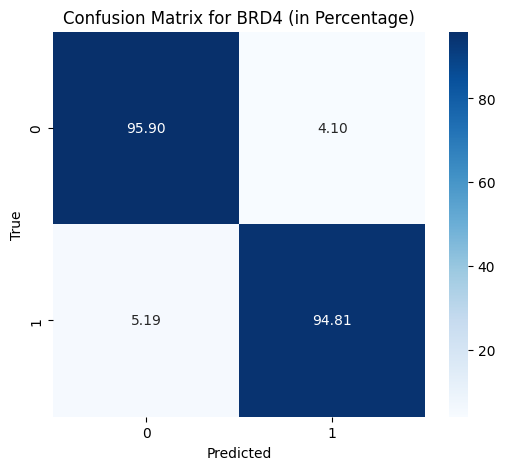

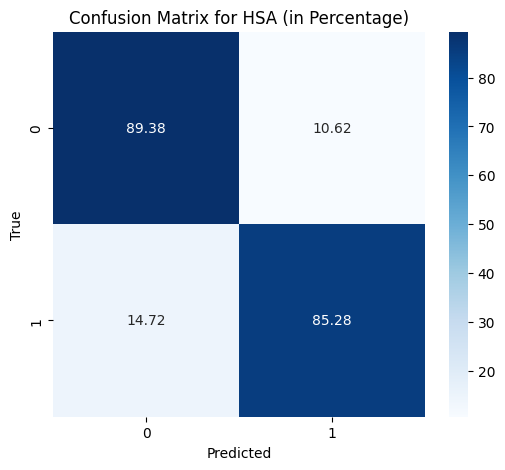

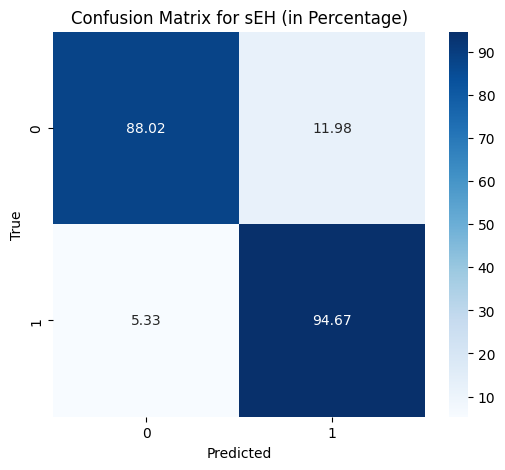

Classification Report:
               precision    recall  f1-score   support

        BRD4       0.90      0.95      0.92     68545
         HSA       0.73      0.85      0.79     61261
         sEH       0.87      0.95      0.90    108678

   micro avg       0.84      0.92      0.88    238484
   macro avg       0.83      0.92      0.87    238484
weighted avg       0.84      0.92      0.88    238484
 samples avg       0.82      0.87      0.83    238484



d:\leash-BELKA\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\leash-BELKA\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\leash-BELKA\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [16]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# For a batch of predictions
@torch.no_grad()
def evaluate_metrics(model, loader, threshold=0.5):
    model.eval()
    all_preds, all_labels = [], []

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = model(input_ids=input_ids, attention_mask=attention_mask)
        probs = torch.sigmoid(logits).cpu().numpy()
        preds = (probs >= threshold).astype(int)

        all_preds.append(preds)
        all_labels.append(labels.cpu().numpy())

    all_preds = np.concatenate(all_preds, axis=0)
    all_labels = np.concatenate(all_labels, axis=0)

    # Confusion matrix per class (in percentage)
    for i, label_name in enumerate(CFG.label_cols):
        cm = confusion_matrix(all_labels[:, i], all_preds[:, i])
        
        # Normalize the confusion matrix to get percentages
        cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
        
        # Plot confusion matrix as percentage
        plt.figure(figsize=(6, 5))
        sns.heatmap(cm_percent, annot=True, fmt=".2f", cmap="Blues", xticklabels=[0, 1], yticklabels=[0, 1])
        plt.title(f"Confusion Matrix for {label_name} (in Percentage)")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.show()

    # Classification report (precision, recall, F1)
    report = classification_report(all_labels, all_preds, target_names=CFG.label_cols)
    print("Classification Report:\n", report)

# Call the function to evaluate metrics
evaluate_metrics(model, valid_loader)


RobertaSdpaSelfAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embedding_type` or `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


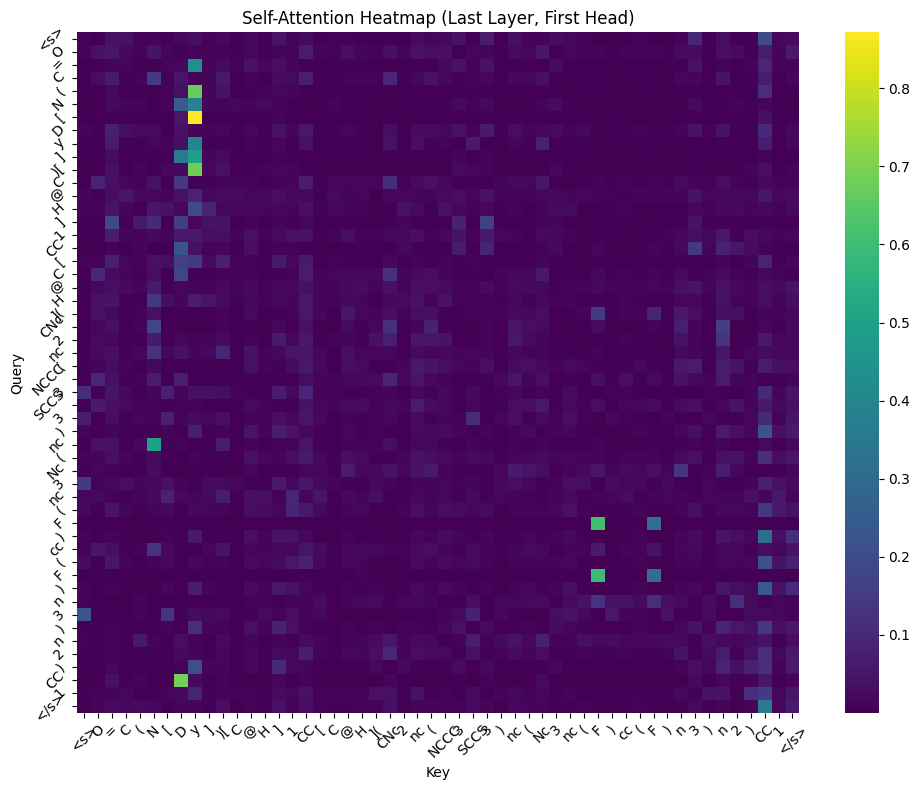

In [17]:
from transformers import AutoTokenizer, AutoModel
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Load tokenizer and model with attention
tokenizer = AutoTokenizer.from_pretrained("seyonec/ChemBERTa-zinc-base-v1")
model = AutoModel.from_pretrained("seyonec/ChemBERTa-zinc-base-v1", output_attentions=True)
model.eval()

# Example SMILES input
smiles = "O=C(N[Dy])[C@H]1CC[C@H](CNc2nc(NCCC3SCCS3)nc(Nc3nc(F)cc(F)n3)n2)CC1"  
inputs = tokenizer(smiles, return_tensors="pt", padding=True, truncation=True, max_length=512)

# Ensure model is set to the same device as inputs
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
inputs = {key: value.to(device) for key, value in inputs.items()}

# Get model output including attention weights
with torch.no_grad():
    outputs = model(**inputs)

# Extract attention from the last layer and head
attn = outputs.attentions[-1][0][0]  # shape: [seq_len, seq_len]

# Convert tokens to readable format
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

# Plot attention matrix
plt.figure(figsize=(10, 8))
sns.heatmap(attn.cpu().numpy(), xticklabels=tokens, yticklabels=tokens, cmap="viridis")
plt.title("Self-Attention Heatmap (Last Layer, First Head)")
plt.xlabel("Key")
plt.ylabel("Query")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.tight_layout()
plt.show()
